EXPERIMENT NO. 4 A (Group A) 
 
Aim: Implement K-Means clustering on Iris.csv dataset. Determine the number of clusters using the elbow 
method.Dataset Link: https://www.kaggle.com/datasets/uciml/iris

Name:Aditya Rade
Roll.No:BEAD23167

Outputs:

Step 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

Step 2 — Load Iris dataset

In [2]:
data = pd.read_csv("Iris.csv")

print(data.head())
print("\nShape:")
print(data.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Shape:
(150, 6)


Step 3 — Remove unnecessary columns

In [3]:
data = data.drop("Id", axis=1)

print(data.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa


Step 4 — Check missing values

In [4]:
print(data.isnull().sum())

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


Step 5 — Select features

In [5]:
X = data[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

Step 6 — Elbow Method

In [6]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    wcss.append(kmeans.inertia_)

print(wcss)

[680.8244000000001, 152.36870647733906, 78.940841426146, 57.317873214285704, 46.53558205128205, 38.930963049671746, 34.36020891600984, 30.023416358198972, 28.14550248961776, 25.95154437229438]


Step 7 — Plot Elbow

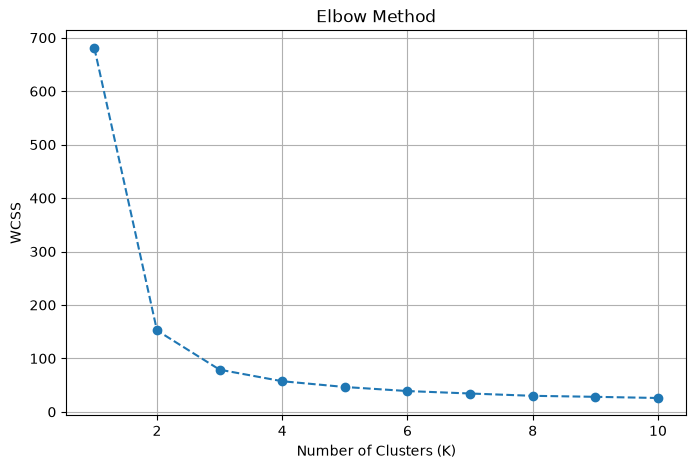

Name:Aditya Rade Roll No:BEAD23167


In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o",
    linestyle="--"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()

plt.show()
print("Name:Aditya Rade Roll No:BEAD23167")

Step 8 — Apply K-Means

In [9]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

data["Cluster"] = clusters

print(data.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0            5.1           3.5            1.4           0.2  Iris-setosa   
1            4.9           3.0            1.4           0.2  Iris-setosa   
2            4.7           3.2            1.3           0.2  Iris-setosa   
3            4.6           3.1            1.5           0.2  Iris-setosa   
4            5.0           3.6            1.4           0.2  Iris-setosa   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  


Step 9 — Display centroids

In [10]:

print("Cluster Centroids:")
print(kmeans.cluster_centers_)

Cluster Centroids:
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.418      1.464      0.244     ]
 [6.85       3.07368421 5.74210526 2.07105263]]


Step 10 — Visualize clusters

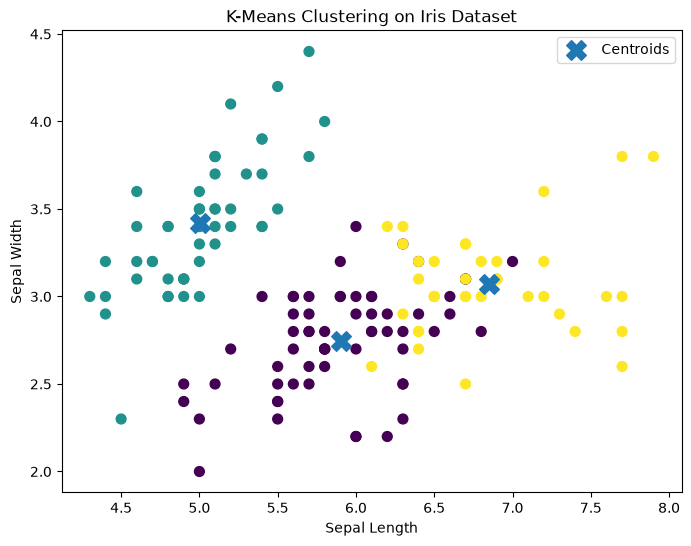

Name:Aditya Rade Roll No:BEAD23167


In [12]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=clusters,
    cmap="viridis",
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    marker="X",
    label="Centroids"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("K-Means Clustering on Iris Dataset")
plt.legend()

plt.show()

print("Name:Aditya Rade Roll No:BEAD23167")